# Variable-aerodynamics trajectory model

Uses speed-dependent drag and an assumed Magnus-spin vector. Launch velocity is fitted to the two measured positions and the goal-plane impact is event-interpolated. The spin and aerodynamic laws are assumptions, not measured properties of this kick.


In [45]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
import seaborn as sns


sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 300,
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "legend.fontsize": 10,
})

In [46]:
def run_kathmandu_simulation(omega_vector=None):
    if omega_vector is None:
        omega_vector = np.array([5.0, 10.0, 32.0])
   
    m = 0.43             # Mass of FIFA regulation ball (kg)
    r = 0.11             # Radius of ball (m)
    A = np.pi * r**2     # Cross-sectional area (m^2)
    g = 9.81             # Gravity (m/s^2)
    
    altitude = 1400.0    # Kathmandu Valley altitude (m)
    mu = 1.81e-5         # Dynamic viscosity of air (Pa·s)
    omega = omega_vector # Angular velocity vector (rad/s)

    # --- Observation Data Points ---
    r0 = np.array([0.0, 0.0, 0.11])  # t = 0.00 s
    r1 = np.array([1.50, 0.45, 0.44])  # t = 0.05 s
    r2 = np.array([2.96, 0.86, 0.74])  # t = 0.10 s
    dt = 0.05  # Time interval between consecutive observed points
    observation_times = np.array([dt, 2 * dt])
    sigma_position = 0.005  # Assumed independent coordinate noise (m)

    # --- Aerodynamic Functions ---
    def get_Cd(v_mag):
        v_crit = 18.0
        Cd_turb, Cd_lam = 0.20, 0.42
        return Cd_lam - (Cd_lam - Cd_turb) / (1.0 + np.exp(-0.5 * (v_mag - v_crit)))

    def get_Cl(v_mag, omega_mag):
        if v_mag < 0.1 or omega_mag < 0.1:
            return 0.0
        spin_param = (omega_mag * r) / v_mag
        return 0.18 * np.tanh(2.0 * spin_param)

    def ode_system(t, state):
        x, y, z, vx, vy, vz = state
        v = np.array([vx, vy, vz])
        v_mag = np.linalg.norm(v)
        omega_mag = np.linalg.norm(omega)
        
        # Local air density adjusted for ball height z above Kathmandu
        current_rho = 1.225 * np.exp(-max(0.0, altitude + z) / 8450.0)
        Cd = get_Cd(v_mag)
        
        # 1. Quadratic Drag Acceleration Vector
        a_drag = - (current_rho * A * Cd / (2.0 * m)) * v_mag * v
        
        # 2. Magnus Acceleration Vector
        if omega_mag > 0 and v_mag > 0.1:
            Cl = get_Cl(v_mag, omega_mag)
            omega_hat = omega / omega_mag
            v_hat = v / v_mag
            a_magnus = (current_rho * A * r * Cl * omega_mag * v_mag / (2.0 * m)) * np.cross(omega_hat, v_hat)
        else:
            a_magnus = np.zeros(3)
            
        # 3. Gravitational Acceleration Vector
        a_grav = np.array([0.0, 0.0, -g])
        
        a_net = a_drag + a_magnus + a_grav
        return [vx, vy, vz, a_net[0], a_net[1], a_net[2]]

 
    def reach_goal(t, state):
        return state[0] - 11.0
    reach_goal.terminal = True
    reach_goal.direction = 1

    # Fit launch velocity to both measured positions; the finite difference is an initial guess.
    initial_guess = (4 * r1 - r2 - 3 * r0) / (2 * dt)
    observed_positions = np.vstack((r1, r2))

    def observation_residual(v0):
        state0 = np.concatenate((r0, v0))
        fit_sol = solve_ivp(
            ode_system, (0.0, observation_times[-1]), state0,
            t_eval=observation_times, max_step=0.001, rtol=1e-8, atol=1e-10,
        )
        if not fit_sol.success or fit_sol.y.shape[1] != len(observation_times):
            raise RuntimeError(f"Observation fit integration failed: {fit_sol.message}")
        return ((fit_sol.y[:3, :].T - observed_positions) / sigma_position).ravel()

    fit = least_squares(observation_residual, initial_guess, x_scale="jac", max_nfev=100)
    if not fit.success:
        raise RuntimeError(f"Launch-velocity fit failed: {fit.message}")
    v0 = fit.x
    fit_sol = solve_ivp(
        ode_system, (0.0, observation_times[-1]), np.concatenate((r0, v0)),
        t_eval=observation_times, max_step=0.001, rtol=1e-8, atol=1e-10,
    )
    residuals = observed_positions - fit_sol.y[:3, :].T
    fit_rmse = np.sqrt(np.mean(residuals**2))

    # Integrate through the goal crossing and use its interpolated event state exactly.
    sol = solve_ivp(
        ode_system, (0.0, 1.0), np.concatenate((r0, v0)),
        events=reach_goal, max_step=0.001, rtol=1e-8, atol=1e-10,
    )
    if not sol.success:
        raise RuntimeError(f"Goal integration failed: {sol.message}")
    if len(sol.t_events[0]) == 0:
        raise RuntimeError("The simulated ball did not reach the goal plane.")
    t_goal = sol.t_events[0][0]
    event_state = sol.y_events[0][0]
    path = np.column_stack((sol.t, sol.y.T))
    path = np.vstack((path, np.concatenate(([t_goal], event_state))))
    return t_goal, path, event_state, v0, residuals, fit_rmse, r0, r1, r2


# Improvement notes: velocity is fitted to both observations; impact uses the exact
# goal-plane event state. Tracking-noise Monte Carlo and parameter sensitivity are
# reported in Monte_Carlo.ipynb; the assumed spin/aerodynamic model remains conditional.
t_goal, trajectory, impact_state, v0_fit, fit_residuals, fit_rmse, r0, r1, r2 = run_kathmandu_simulation()
x_traj, y_traj, z_traj = trajectory[:, 1], trajectory[:, 2], trajectory[:, 3]
final_y, final_z = impact_state[1], impact_state[2]

print(f"Fitted launch velocity: ({v0_fit[0]:.4f}, {v0_fit[1]:.4f}, {v0_fit[2]:.4f}) m/s")
print(f"Observed - fitted position residuals (mm):\n{(1000 * fit_residuals).round(2)}")
print(f"Coordinate fit RMSE: {1000 * fit_rmse:.2f} mm (assumed tracking sigma = 5 mm)")
print(f"Flight Time to Goal Plane: {t_goal:.4f} s")
print(f"Goal Impact Coordinates: Y = {final_y:.3f} m, Z = {final_z:.3f} m")

 

Fitted launch velocity: (30.0733, 8.7860, 6.8894) m/s
Observed - fitted position residuals (mm):
[[ 7.35 13.66  0.31]
 [-3.74 -6.89 -0.16]]
Coordinate fit RMSE: 7.10 mm (assumed tracking sigma = 5 mm)
Flight Time to Goal Plane: 0.3862 s
Goal Impact Coordinates: Y = 3.229 m, Z = 1.921 m


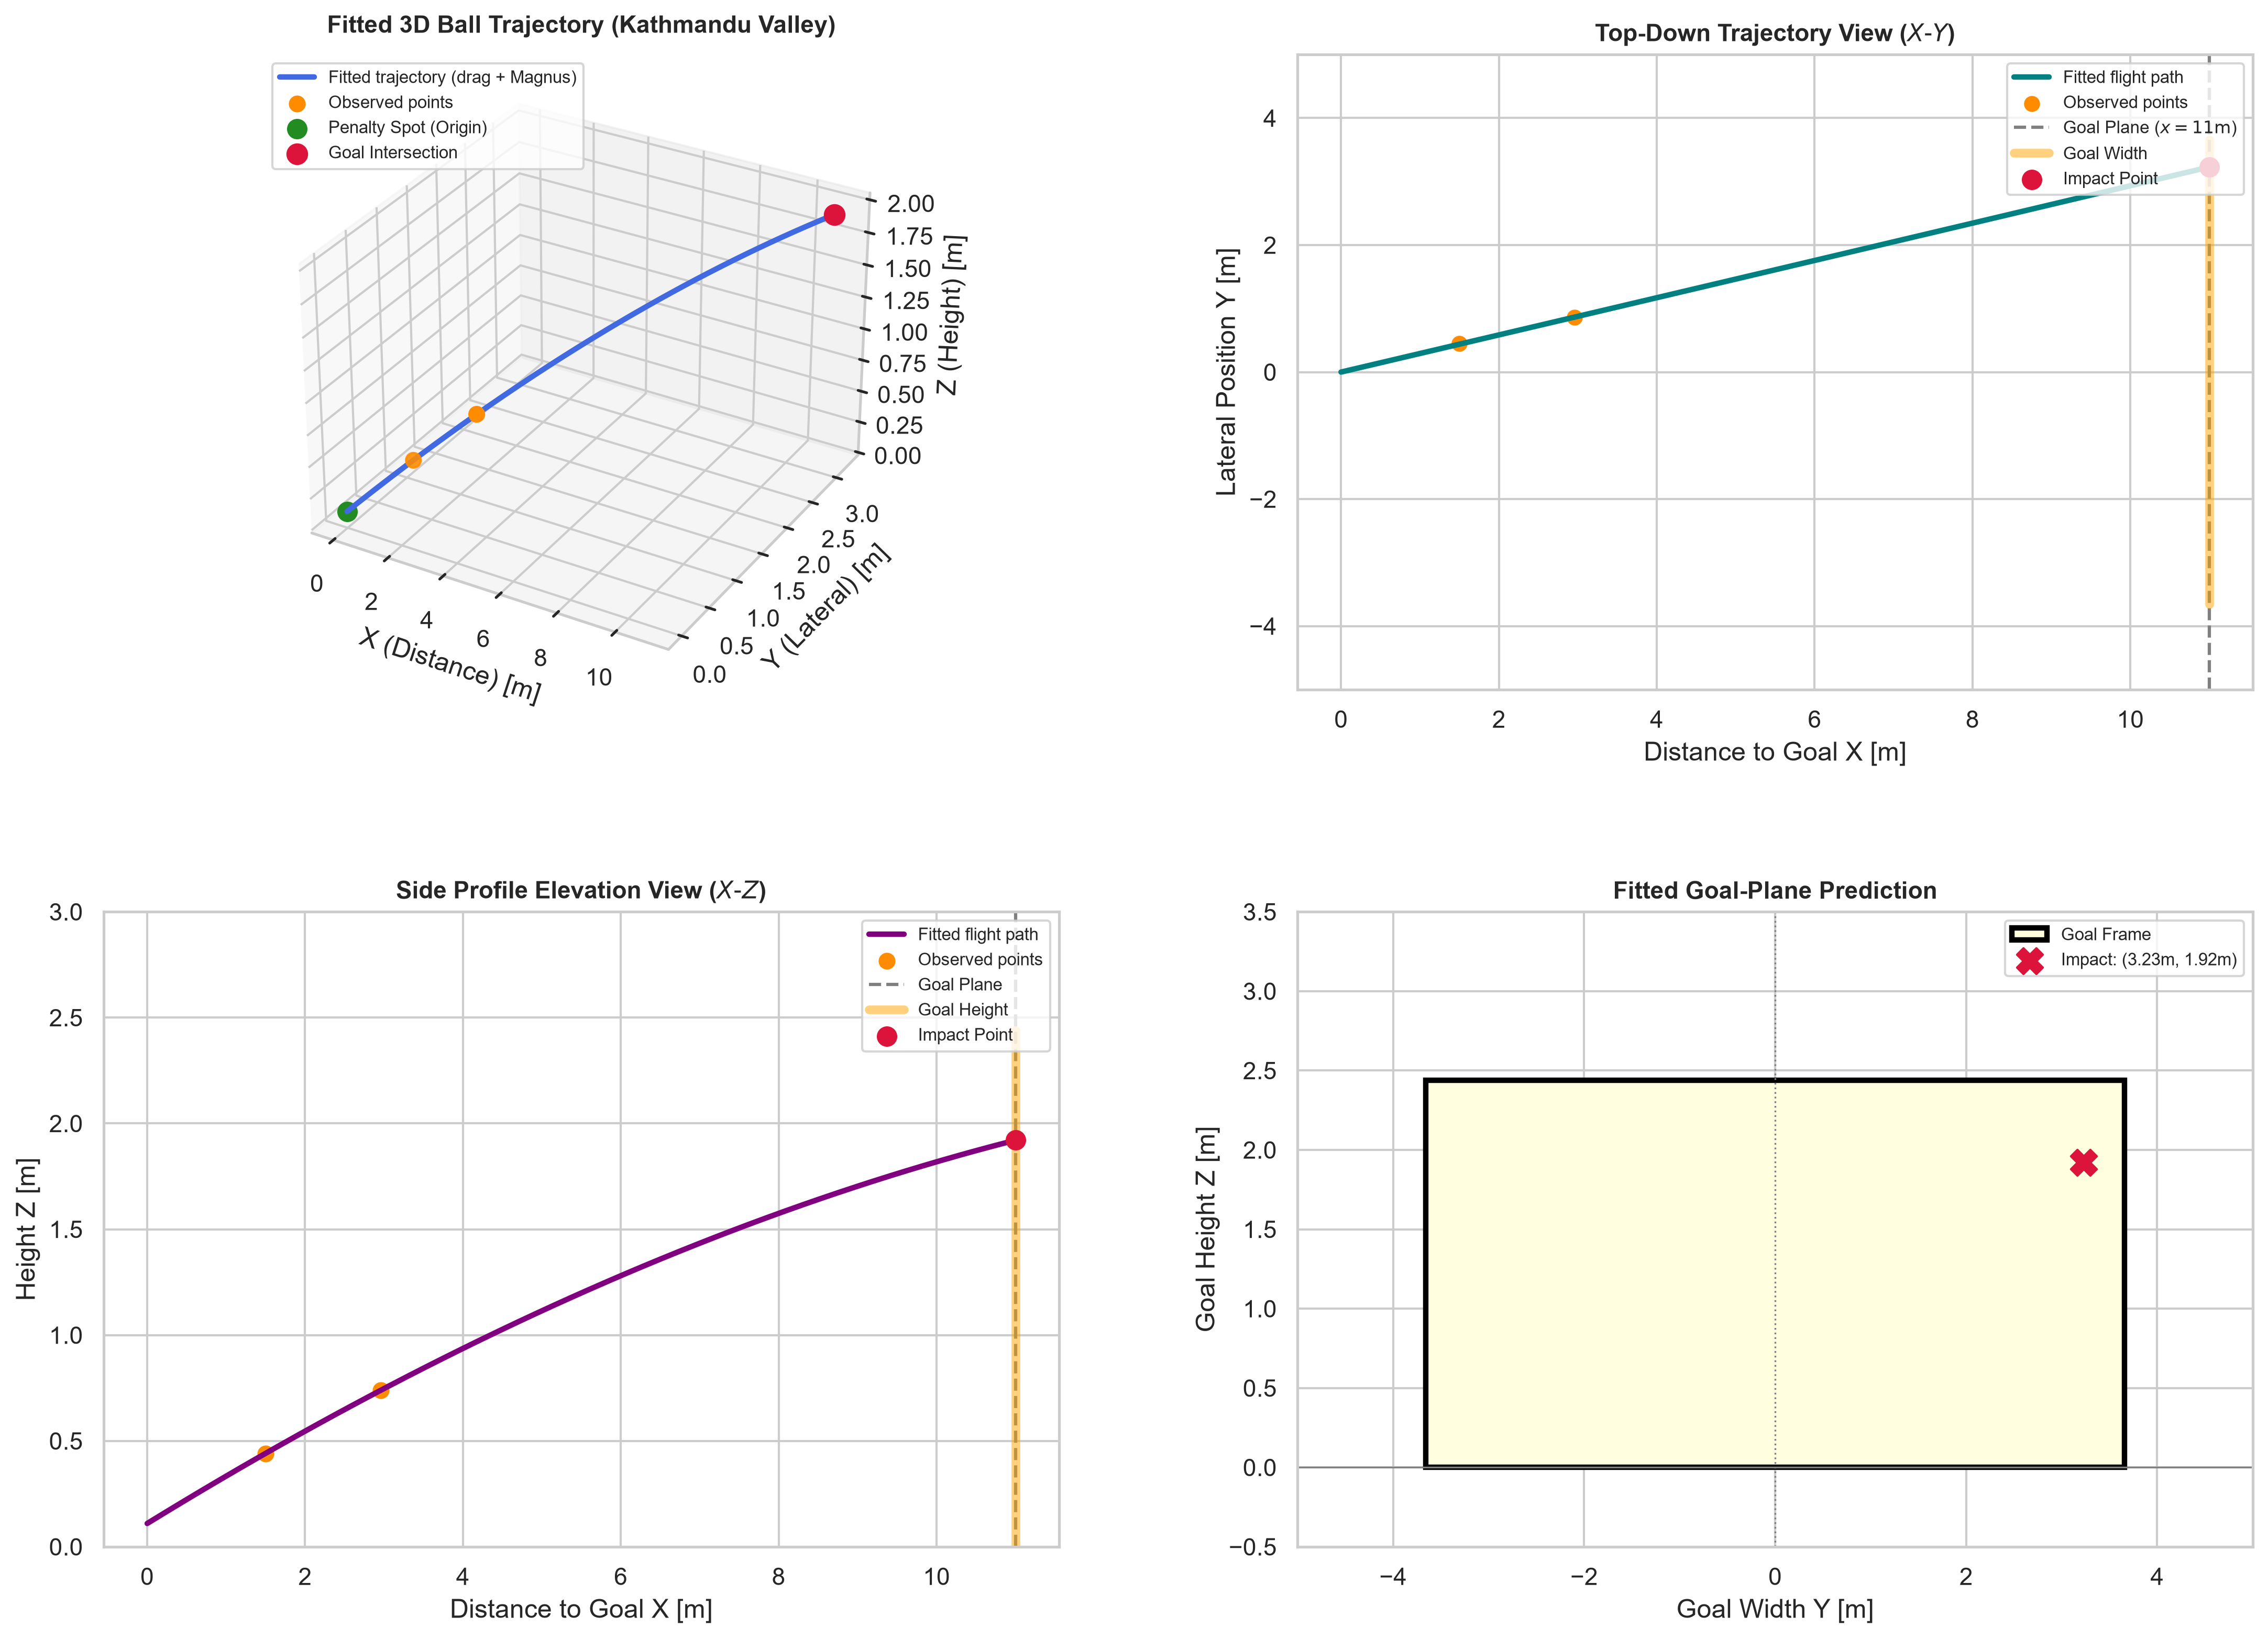

In [50]:


# 1. Increased figure width and height for a 2x2 grid
fig = plt.figure(figsize=(15, 11))

# --- Subplot 1: 3D Trajectory ---
ax1 = fig.add_subplot(221, projection='3d')
ax1.plot(x_traj, y_traj, z_traj, label='Fitted trajectory (drag + Magnus)', color='royalblue', lw=2.5)
ax1.scatter([r1[0], r2[0]], [r1[1], r2[1]], [r1[2], r2[2]], color='darkorange', s=45, label='Observed points')
ax1.scatter([0], [0], [0.11], color='forestgreen', s=70, label='Penalty Spot (Origin)')
ax1.scatter([11.0], [final_y], [final_z], color='crimson', s=80, label='Goal Intersection')

ax1.set_title("Fitted 3D Ball Trajectory (Kathmandu Valley)", fontsize=11, fontweight='bold', pad=10)
ax1.set_xlabel("X (Distance) [m]")
ax1.set_ylabel("Y (Lateral) [m]")
ax1.set_zlabel("Z (Height) [m]")
ax1.legend(loc='upper left', frameon=True, fontsize=8)

# --- Subplot 2: Top-Down X-Y Plane ---
ax2 = fig.add_subplot(222)
ax2.plot(x_traj, y_traj, color='teal', lw=2.5, label='Fitted flight path')
ax2.scatter([r1[0], r2[0]], [r1[1], r2[1]], color='darkorange', s=40, label='Observed points')
ax2.axvline(11.0, color='gray', linestyle='--', label='Goal Plane ($x=11\\text{m}$)')
ax2.plot([11.0, 11.0], [-3.66, 3.66], color='orange', linewidth=4, alpha=0.5, label='Goal Width')
ax2.scatter([11.0], [final_y], color='crimson', s=70, zorder=5, label='Impact Point')

ax2.set_title("Top-Down Trajectory View ($X\\text{-}Y$)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Distance to Goal X [m]")
ax2.set_ylabel("Lateral Position Y [m]")
ax2.set_ylim(-5, 5)
ax2.legend(loc='upper right', frameon=True, fontsize=8)

# --- Subplot 3: Side Profile X-Z Plane ---
ax3 = fig.add_subplot(223)
ax3.plot(x_traj, z_traj, color='purple', lw=2.5, label='Fitted flight path')
ax3.scatter([r1[0], r2[0]], [r1[2], r2[2]], color='darkorange', s=45, label='Observed points')
ax3.axvline(11.0, color='gray', linestyle='--', label='Goal Plane')
ax3.plot([11.0, 11.0], [0.0, 2.44], color='orange', linewidth=4, alpha=0.5, label='Goal Height')
ax3.scatter([11.0], [final_z], color='crimson', s=70, zorder=5, label='Impact Point')

ax3.set_title("Side Profile Elevation View ($X\\text{-}Z$)", fontsize=11, fontweight='bold')
ax3.set_xlabel("Distance to Goal X [m]")
ax3.set_ylabel("Height Z [m]")
ax3.set_ylim(0, 3)
ax3.legend(loc='upper right', frameon=True, fontsize=8)

# --- Subplot 4: Goal-Plane Prediction ---
ax4 = fig.add_subplot(224)
goal_rect = plt.Rectangle((-3.66, 0.0), 7.32, 2.44, linewidth=2.5, edgecolor='black', facecolor='lightyellow', label='Goal Frame')
ax4.add_patch(goal_rect)
ax4.scatter([final_y], [final_z], color='crimson', s=140, marker='X', zorder=5, label=f"Impact: ({final_y:.2f}m, {final_z:.2f}m)")

ax4.set_title("Fitted Goal-Plane Prediction", fontsize=11, fontweight='bold')
ax4.set_xlabel("Goal Width Y [m]")
ax4.set_ylabel("Goal Height Z [m]")
ax4.set_xlim(-5.0, 5.0)
ax4.set_ylim(-0.5, 3.5)
ax4.axhline(0, color='gray', linewidth=0.8)
ax4.axvline(0, color='gray', linewidth=0.8, linestyle=':')
ax4.legend(loc='upper right', frameon=True, fontsize=8)

# --- Layout Adjustments to Prevent Overlap ---
fig.tight_layout(pad=2.5)
fig.subplots_adjust(wspace=0.25, hspace=0.35)

plt.show()